# Tabular 분류 — 시험용 완성 코드

위에서부터 순서대로 실행하세요. **★ 설정**만 데이터에 맞게 바꾸면 됩니다.
확인이 필요한 판단(버릴 컬럼 등)은 **셀을 나눠** 출력을 보고 정하도록 했습니다.
(이진/다중 구분 없이 동작 · 타겟 자동 인코딩 → 제출 때 원래 값 복원)

> 변수명은 **이 파일 단독 실행** 기준(plain)입니다. 시험은 **한 커널**에서 3문제를 이어 풀어 `X`·`best`·`sub` 같은 변수가 서로 덮어써집니다 — 정형=`p1_`, 텍스트=`p2_`, 이미지=`p3_` 접두사로 문제별로 분리하세요.

## 1. 설정 · 로드  ← ★ 여기만 수정

In [4]:
import pandas as pd, numpy as np, joblib
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

SEED = 42
RESULT_1 = '01012345678_1'             # 휴대폰번호_문제번호 (하이픈·공백 없이). Tabular=1

# ▼ 데이터 선택 (하나만) — '파일 여는 것'만. 맞출 컬럼(TARGET)은 데이터 본 뒤 '3.' 에서 정한다
TRAIN_URL = 'https://github.com/gzone2000/TEMP_TEST/raw/refs/heads/master/titanic.csv'              # [1] 타이타닉·이진
# TRAIN_URL = 'https://github.com/gzone2000/TEMP_TEST/raw/refs/heads/master/iris.csv'               # [2] 붓꽃·다중(3)
# TRAIN_URL = 'https://github.com/gzone2000/TEMP_TEST/raw/refs/heads/master/Invistico_Airline.csv'  # [3] 항공사 만족도·이진
# TRAIN_URL = 'https://github.com/gzone2000/TEMP_TEST/raw/refs/heads/master/otto.csv'               # [4] Otto 상품·다중(9)
TEST_URL = None                        # test 파일 따로 있으면 URL, 없으면 None(train 에서 분리)

df_all = pd.read_csv(TRAIN_URL)                        # 원본(불변) — 분할은 타겟 정한 뒤 '3.' 에서
df_test_raw = pd.read_csv(TEST_URL) if TEST_URL else None
print('불러온 데이터:', df_all.shape, '| test 파일:', df_test_raw.shape if TEST_URL else '없음(train 에서 분리)')
df_all.head()

불러온 데이터: (891, 12) | test 파일: 없음(train 에서 분리)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. 데이터 확인  (컬럼·타입·결측을 보고 아래에서 맞출/버릴 컬럼을 정한다)

In [5]:
print(df_all.dtypes)
# 고유값이 행수에 가까운 컬럼 = ID/이름 → 버릴 후보 · 타겟과 완벽히 일치하면 누수 컬럼
print(); print('컬럼별 고유값 수:'); print(df_all.nunique().sort_values(ascending=False))
print(); print('결측:', df_all.isnull().sum()[lambda s: s > 0].to_dict())

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

컬럼별 고유값 수:
PassengerId    891
Name           891
Ticket         681
Fare           248
Cabin          147
Age             88
SibSp            7
Parch            7
Embarked         3
Pclass           3
Survived         2
Sex              2
dtype: int64

결측: {'Age': 177, 'Cabin': 687, 'Embarked': 2}


## 3. 맞출 컬럼 지정 · 분할  ← ★ 위 '데이터 확인'을 보고 채운다

In [6]:
# ★ 위 컬럼 목록에서 '맞출 컬럼'을 직접 지정 (지문이 준 이름과 철자가 같은지 확인)
TARGET = 'Survived'          # [1] 타이타닉 · [2] iris:'variety' · [3] 항공:'satisfaction' · [4] otto:'target'
PRED_COL = TARGET            # 제출 결과 컬럼명 — 지문이 다른 이름을 지정하면 그 이름으로 바꾼다

print('타겟 분포(문자/숫자 확인):'); print(df_all[TARGET].value_counts())

# test 가 따로 없으면 여기서 분리 (분류는 stratify=타겟). df_all 은 원본이라 재실행해도 안전
if df_test_raw is None:
    df, df_test = train_test_split(df_all, test_size=0.2, random_state=SEED, stratify=df_all[TARGET])
else:
    df, df_test = df_all.copy(), df_test_raw.copy()
df, df_test = df.reset_index(drop=True), df_test.reset_index(drop=True)
df_test_orig = df_test.copy()          # 제출은 test 원본 구조로
print('Train', df.shape, '/ Test', df_test.shape)

타겟 분포(문자/숫자 확인):
Survived
0    549
1    342
Name: count, dtype: int64
Train (712, 12) / Test (179, 12)


## 4. 상관 히트맵  (숫자 컬럼 ↔ 타겟)

타겟과 상관이 강한 컬럼 = 좋은 예측변수. **|r|이 1에 가까우면 누수** 의심(드롭 후보).
숫자 컬럼만 계산하며, 문자 타겟은 상관 계산을 위해 임시 인코딩합니다.

타겟과 상관(|r|) 상위:
{'Pclass': 0.348, 'Fare': 0.275, 'Age': 0.084, 'Parch': 0.084, 'SibSp': 0.026, 'PassengerId': 0.012}


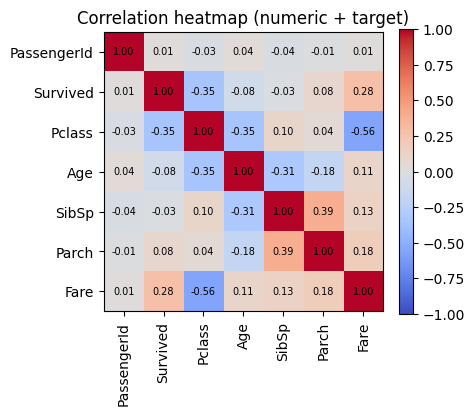

In [7]:
import matplotlib.pyplot as plt
num = df.select_dtypes('number').copy()
if TARGET not in num.columns:                       # 문자 타겟이면 상관 계산 위해 임시 인코딩
    num[TARGET] = LabelEncoder().fit_transform(df[TARGET].astype(str))
corr = num.corr(numeric_only=True)

# 타겟과 상관 큰 순 (|r|=1 이면 누수 의심, 클수록 강한 예측변수)
tcorr = corr[TARGET].drop(TARGET).abs().sort_values(ascending=False)
print('타겟과 상관(|r|) 상위:'); print(tcorr.head(10).round(3).to_dict())

# 컬럼이 많으면(>15) 타겟 + 상관 상위 12개만 그린다 (전체는 너무 커서 안 보임)
cols = ([TARGET] + tcorr.head(12).index.tolist()) if len(corr) > 15 else corr.columns.tolist()
cm = corr.loc[cols, cols]
plt.figure(figsize=(min(1 + 0.55 * len(cols), 11), min(1 + 0.55 * len(cols), 11)))
plt.imshow(cm, cmap='coolwarm', vmin=-1, vmax=1); plt.colorbar(fraction=0.046)
plt.xticks(range(len(cols)), cols, rotation=90); plt.yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        plt.text(j, i, f'{cm.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7)
plt.title('Correlation heatmap (numeric + target)'); plt.tight_layout(); plt.show()

## 5. 버릴 컬럼 결정  ← ★ 위 '데이터 확인'을 보고 채운다

In [9]:
# ── 버릴 후보 자동 점검 (참고용, df=train 기준) ──
n = len(df)
card = (df.drop(columns=[TARGET]).nunique() / n).sort_values(ascending=False)
print('① 고유값/행수 비율(1에 가까울수록 ID·이름 후보):')
print('  ', {k: round(v, 3) for k, v in card.head(6).items()})
print('   → 비율 0.9 초과:', [c for c in card.index if card[c] > 0.9] or '없음')
# ② 그 컬럼값만 알면 타겟이 하나로 정해지는 컬럼 = 누수 의심 (ID 는 nunique<n 으로 제외)
leak = [c for c in df.columns if c != TARGET and 1 < df[c].nunique() < n
        and df.groupby(c)[TARGET].nunique().max() == 1]
print('② 타겟과 완벽히 일치(누수 의심):', leak or '없음')


① 고유값/행수 비율(1에 가까울수록 ID·이름 후보):
   {'PassengerId': 1.0, 'Name': 1.0, 'Ticket': 0.802, 'Fare': 0.317, 'Cabin': 0.178, 'Age': 0.119}
   → 비율 0.9 초과: ['PassengerId', 'Name']
② 타겟과 완벽히 일치(누수 의심): 없음


In [10]:
# ★ 위 ①②와 상식을 보고 버릴 컬럼을 직접 적는다 (①=ID/이름, ②=누수)
DROP_COLS = ['PassengerId', 'Name']   # [1] 타이타닉
# [2] 붓꽃:   DROP_COLS = []
# [3] 항공사: DROP_COLS = []   (필요 시 id 류 추가)
# [4] Otto:   DROP_COLS = ['id']
print('버릴 컬럼:', [c for c in DROP_COLS if c in df.columns])
print('남는 피처:', [c for c in df.columns if c not in DROP_COLS + [TARGET]])

버릴 컬럼: ['PassengerId', 'Name']
남는 피처: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


## 6. 전처리  (결측 → 인코딩 → 스케일)

In [11]:
has_y_test = TARGET in df_test.columns
X      = df.drop(columns=[c for c in DROP_COLS + [TARGET] if c in df.columns], errors='ignore')
X_test = df_test.drop(columns=[c for c in DROP_COLS + [TARGET] if c in df_test.columns], errors='ignore')

# 수치형/범주형 분리 — 결측 채우는 방법이 다르므로 먼저 나눈다
num = X.select_dtypes('number').columns.tolist()   # 숫자형 (나이·요금 등)
cat = [c for c in X.columns if c not in num]        # 나머지 = 범주형 (성별·도시 등 문자)

# 결측치 채우기 — ★ train 에서 fit(채울 값 계산) → test 는 transform(그 값으로만 채움).
#   fit 을 test 로 하면 test 정보가 새어들어(누수) 점수가 헛되게 오른다.
if num:
    imp_n = SimpleImputer(strategy='median')        # 수치형: 중앙값 (이상치에 강건)
    X[num] = imp_n.fit_transform(X[num]); X_test[num] = imp_n.transform(X_test[num])
if cat:
    imp_c = SimpleImputer(strategy='most_frequent') # 범주형: 최빈값 (가장 흔한 값)
    X[cat] = imp_c.fit_transform(X[cat]); X_test[cat] = imp_c.transform(X_test[cat])

# 범주형 인코딩 (train 사전으로 test 변환, 미지값은 -1)
for col in cat:
    le = LabelEncoder().fit(X[col].astype(str))
    m = {v: i for i, v in enumerate(le.classes_)}
    X[col] = X[col].astype(str).map(m)
    X_test[col] = X_test[col].astype(str).map(m).fillna(-1).astype(int)

# 타겟 인코딩(정수) — 제출 때 inverse_transform 으로 원래 값 복원
ty = LabelEncoder()
y = ty.fit_transform(df[TARGET])
y_test = ty.transform(df_test[TARGET]) if has_y_test else None

# 스케일링
sc = StandardScaler()
X = pd.DataFrame(sc.fit_transform(X), columns=X.columns)
X_test = pd.DataFrame(sc.transform(X_test), columns=X_test.columns)
print('수치형', len(num), '· 범주형', len(cat), '· 클래스', list(ty.classes_))

수치형 5 · 범주형 4 · 클래스 [np.int64(0), np.int64(1)]


## 7. 모델 비교 · 학습 · 평가

In [12]:
Xtr, Xva, ytr, yva = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)

models = {
    'LogReg':       LogisticRegression(max_iter=1000, random_state=SEED),
    'RandomForest': RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    'GradBoost':    GradientBoostingClassifier(random_state=SEED),
}
cv = {n: cross_val_score(m, Xtr, ytr, cv=5).mean() for n, m in models.items()}
best_name = max(cv, key=cv.get)
best = models[best_name].fit(Xtr, ytr)
print('CV:', {n: round(s, 4) for n, s in cv.items()}, '→ 1위', best_name)

yva_pred = best.predict(Xva)
print(f"Val Acc {accuracy_score(yva, yva_pred):.4f} / F1(macro) {f1_score(yva, yva_pred, average='macro'):.4f}")
print(classification_report(yva, yva_pred, target_names=[str(c) for c in ty.classes_]))

CV: {'LogReg': np.float64(0.7979), 'RandomForest': np.float64(0.8137), 'GradBoost': np.float64(0.8172)} → 1위 GradBoost
Val Acc 0.8322 / F1(macro) 0.8201
              precision    recall  f1-score   support

           0       0.85      0.89      0.87        88
           1       0.80      0.75      0.77        55

    accuracy                           0.83       143
   macro avg       0.83      0.82      0.82       143
weighted avg       0.83      0.83      0.83       143



## 8. 결과 만들고 ⭐ 눈으로 확인

> 예측을 **원래 라벨로 복원**(숫자 그대로면 0점) 후, **저장 전에** 예측이 상식적으로 맞는지 눈으로 봅니다.

In [13]:
pred = ty.inverse_transform(best.predict(X_test))      # 정수 예측 → 원래 라벨 복원

sub = df_test_orig.drop(columns=[c for c in [TARGET] if c in df_test_orig.columns]).copy()
sub[PRED_COL] = pred

# ★ 눈으로 확인 (저장 전에)
print('행수', len(sub), '| 컬럼', list(sub.columns))
print('예측 분포:', sub[PRED_COL].value_counts().to_dict())
if has_y_test:
    print('Test Acc', round(accuracy_score(y_test, best.predict(X_test)), 4))
sub.head(10)

행수 179 | 컬럼 ['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked', 'Survived']
예측 분포: {0: 113, 1: 66}
Test Acc 0.7933


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Survived
0,566,3,"Davies, Mr. Alfred J",male,24.0,2,0,A/4 48871,24.1500,NaN,S,0
1,161,3,"Cribb, Mr. John Hatfield",male,44.0,0,1,371362,16.1000,NaN,S,0
2,554,3,"Leeni, Mr. Fahim (""Philip Zenni"")",male,22.0,0,0,2620,7.2250,NaN,C,0
3,861,3,"Hansen, Mr. Claus Peter",male,41.0,2,0,350026,14.1083,NaN,S,0
4,242,3,"Murphy, Miss. Katherine ""Kate""",female,NaN,1,0,367230,15.5000,NaN,Q,1
5,560,3,"de Messemaeker, Mrs. Guillaume Joseph (Emma)",female,36.0,1,0,345572,17.4000,NaN,S,1
6,388,2,"Buss, Miss. Kate",female,36.0,0,0,27849,13.0000,NaN,S,1
7,537,1,"Butt, Major. Archibald Willingham",male,45.0,0,0,113050,26.5500,B38,S,0
8,699,1,"Thayer, Mr. John Borland",male,49.0,1,1,17421,110.8833,C68,C,1
9,100,2,"Kantor, Mr. Sinai",male,34.0,1,0,244367,26.0000,NaN,S,0


## 9. ⭐ csv · 모델 저장

> 위 결과가 이상 없으면 저장합니다. `휴대폰_문제.csv` + 모델(`.pkl`), `index=False` 필수.

In [14]:
import os
CSV, MODEL = f'{RESULT_1}.csv', f'{RESULT_1}.pkl'
assert len(sub) == len(df_test_orig), '행 수 불일치'      # ★ 저장 전에 검증 (0점 나는 두 원인)
assert sub[PRED_COL].isnull().sum() == 0, '예측 결측'
sub.to_csv(CSV, index=False)     # 결과 csv
joblib.dump(best, MODEL)                                # 모델
print('저장 완료:', [f for f in os.listdir('.') if f.startswith(RESULT_1)])

저장 완료: ['01012345678_1.pkl', '01012345678_1.csv']
